# Modularity on the Karate Club Graph
**DSC212: Graph Theory – Research Assignment**

Recursive spectral modularity partitioning (Newman, 2006, *Modularity and community structure in networks*, PNAS 103(23):8577–8582), implemented from scratch with NumPy + NetworkX, followed by per-split visualisation and node-metric evolution.

**Contents**
1. Setup and data
2. Modularity matrix and the two-community split
3. Recursive bisection
4. Visualisation after every split
5. Node metrics after every split
6. Evolution of the metrics
7. Discussion
8. Extra: the handout's block-restricted matrix vs. Newman's generalised matrix

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 110

G = nx.karate_club_graph()
nodes = sorted(G.nodes())            # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n} nodes, m = {m} edges")

# Adjacency matrix A (rows/cols ordered by node id) and degree vector k
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency
k = A.sum(axis=1)
assert np.allclose(A, A.T) and k.sum() == 2 * m

# Ground truth split recorded by Zachary ('Mr. Hi' vs 'Officer')
truth = np.array([+1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in nodes])
print("Mr. Hi group size:", (truth == 1).sum(), "| Officer group size:", (truth == -1).sum())

n = 34 nodes, m = 78 edges
Mr. Hi group size: 17 | Officer group size: 17


## 1. The modularity matrix
$$B = A - \frac{k k^\top}{2m},\qquad Q(s)=\frac{1}{4m}\,s^\top B s .$$
We check the facts proved in the handout numerically: $B$ is real symmetric (Prop. 1), $B\mathbf 1 = 0$ (Prop. 2), and therefore the trivial partition has $Q=0$ (Cor. 1).

In [2]:
B = A - np.outer(k, k) / (2 * m)

print("B symmetric          :", np.allclose(B, B.T))
print("max |B @ 1|          :", np.abs(B @ np.ones(n)).max())
print("Q(all in one group)  :", np.ones(n) @ B @ np.ones(n) / (4 * m))

def modularity_Q(s, B=B, m=m):
    """Q = s^T B s / 4m for a +/-1 label vector s over all nodes."""
    s = np.asarray(s, dtype=float)
    return s @ B @ s / (4 * m)

print("Q(ground-truth split):", round(modularity_Q(truth), 4))

B symmetric          : True
max |B @ 1|          : 8.881784197001252e-16
Q(all in one group)  : 8.718097469011646e-18
Q(ground-truth split): 0.3582


## 2. Spectral bipartition of one group
For a group `C` (list of node ids) we take the block $B^{(C)}$ of the global $B$, compute its leading eigenpair with `numpy.linalg.eigh` (valid because $B^{(C)}$ is real symmetric), and split by the sign of the leading eigenvector (entries $\le 0$ go to the $-1$ side, as in the handout).

*Pseudocode*
```
spectral_split(C):
    B_C  <- B[C, C]                     # |C| x |C|
    lam, U <- eigh(B_C)                 # ascending eigenvalues
    lam1, u1 <- lam[-1], U[:, -1]
    if lam1 <= tol: return None          # indivisible
    s <- +1 where u1 > 0, else -1
    if s is all +1 or all -1: return None
    return C+, C-, lam1, dQ = s^T B_C s / 4m
```

In [3]:
TOL = 1e-10

def spectral_split(C, B=B, m=m, tol=TOL):
    """Try to bisect group C (list of node ids) using the leading eigenvector of B[C,C].
    Returns (C_plus, C_minus, lam1, dQ), or None if C is indivisible."""
    C = list(C)
    if len(C) < 2:
        return None
    B_C = B[np.ix_(C, C)]
    vals, vecs = np.linalg.eigh(B_C)          # ascending order
    lam1, u1 = vals[-1], vecs[:, -1]
    if lam1 <= tol:                           # Theorem 3: no split can help
        return None
    s = np.where(u1 > 0, 1, -1)
    if abs(s.sum()) == len(s):                # all on one side -> not a real split
        return None
    C_plus  = [c for c, si in zip(C, s) if si == +1]
    C_minus = [c for c, si in zip(C, s) if si == -1]
    dQ = s @ B_C @ s / (4 * m)
    return C_plus, C_minus, lam1, dQ

# First split of the whole graph
Cp, Cm, lam1, dQ = spectral_split(nodes)
print("lambda_1 =", round(lam1, 4), "| Q after split =", round(dQ, 4))
print("Group +:", Cp)
print("Group -:", Cm)

pred = np.array([+1 if i in Cp else -1 for i in nodes])
agree = max((pred == truth).mean(), (pred == -truth).mean())
wrong = [i for i in nodes if pred[i] != (truth[i] if (pred == truth).mean() >= 0.5 else -truth[i])]
print(f"Agreement with real split: {agree:.1%}; misclassified node(s): {wrong}")

lambda_1 = 4.9771 | Q after split = 0.3715
Group +: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group -: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Agreement with real split: 97.1%; misclassified node(s): [8]


## 3. Recursive bisection
Groups are processed first-in-first-out. **One iteration = one successful split.** After each iteration we store the full partition so it can be visualised and used for the metrics. Iteration 0 is the whole graph as a single community.

In [4]:
def recursive_spectral_partition(nodes, B=B, m=m, split_fn=spectral_split):
    """Recursive bisection. Returns (history, log):
       history[t] = list of communities (lists of node ids) after t splits (t=0: whole graph)
       log[t]     = dict describing split t (parent, children, lambda_1, dQ, Q_total)"""
    communities = [list(nodes)]
    history = [[c[:] for c in communities]]
    log = [dict(iteration=0, parent=None, children=None, lam1=None, dQ=None,
                Q=0.0, n_communities=1)]
    queue = deque([list(nodes)])
    while queue:
        C = queue.popleft()
        out = split_fn(C, B, m)
        if out is None:
            continue                                   # C is final
        Cp, Cm, lam1, dQ = out
        communities = [c for c in communities if c != C] + [Cp, Cm]
        queue.extend([Cp, Cm])
        history.append([c[:] for c in communities])
        log.append(dict(iteration=len(history) - 1, parent=C, children=(Cp, Cm),
                        lam1=lam1, dQ=dQ, Q=partition_modularity(communities),
                        n_communities=len(communities)))
    return history, log

def partition_modularity(communities, B=B, m=m):
    """Total Q of a partition = (1/2m) * sum_c sum_{i,j in c} B_ij."""
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)

history, log = recursive_spectral_partition(nodes)
n_iter = len(history) - 1

summary = pd.DataFrame([{k_: v for k_, v in row.items() if k_ not in ("parent", "children")} for row in log])
summary["split_sizes"] = [None] + [f"{len(r['parent'])} -> {len(r['children'][0])} + {len(r['children'][1])}" for r in log[1:]]
display(summary.round(4))

final = history[-1]
print("\nFinal communities:")
for idx, c in enumerate(sorted(final, key=lambda c: -len(c))):
    print(f"  C{idx+1} (size {len(c)}): {sorted(c)}")
print("Final modularity Q =", round(partition_modularity(final), 4))

# sanity check: matches NetworkX's modularity for the same partition
print("NetworkX modularity of same partition =",
      round(nx.community.modularity(G, [set(c) for c in final], weight=None), 4))

,iteration,lam1,dQ,Q,n_communities,split_sizes
0,0,NaN,NaN,0.0000,1,NaN
1,1,4.9771,0.3715,0.3715,2,34 -> 16 + 18
2,2,2.9441,0.1112,0.3898,3,16 -> 10 + 6
3,3,2.5041,0.1112,0.4081,4,18 -> 5 + 13
4,4,2.1480,0.0338,0.4094,5,6 -> 1 + 5



Final communities:
  C1 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C2 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C3 (size 5): [24, 25, 27, 28, 31]
  C4 (size 5): [4, 5, 6, 10, 16]
  C5 (size 1): [11]
Final modularity Q = 0.4094
NetworkX modularity of same partition = 0.4094


## 4. Visualisation after every split
A single **fixed spring layout** (seeded) is reused for every panel so only the colours change. Each community has a unique colour (kept stable by always colouring in the order of the final partition's hierarchy), and nodes are labelled by id.

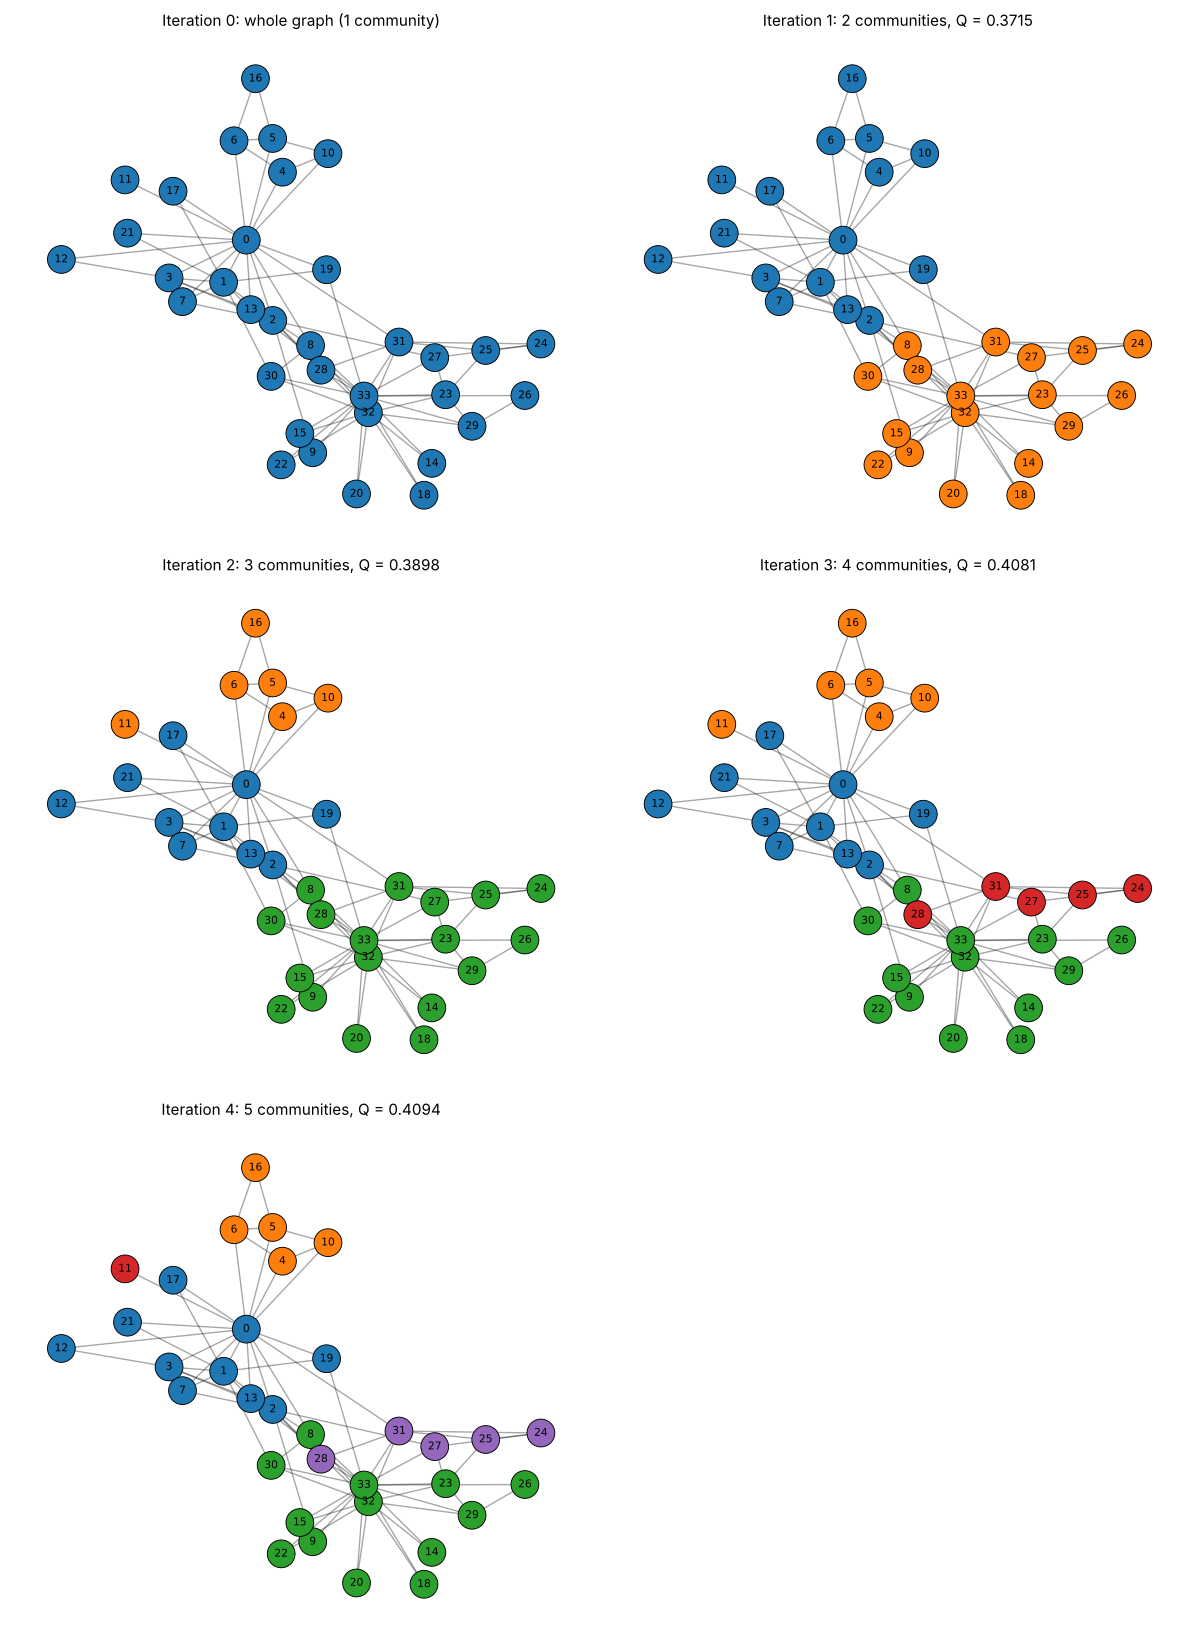

In [5]:
pos = nx.spring_layout(G, seed=42)            # fixed layout reused everywhere

def community_colors(communities):
    # sort by (smallest node id) so colour assignment is deterministic
    comms = sorted(communities, key=lambda c: min(c))
    cmap = plt.get_cmap("tab10")
    color_of = {}
    for ci, c in enumerate(comms):
        for v in c:
            color_of[v] = cmap(ci % 10)
    return [color_of[v] for v in nodes]

def draw_partition(ax, communities, title):
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=community_colors(communities),
                           node_size=330, edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

cols = 2
rows = int(np.ceil((n_iter + 1) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(11, 5 * rows))
axes = np.atleast_2d(axes).ravel()
for t, comms in enumerate(history):
    ttl = "Iteration 0: whole graph (1 community)" if t == 0 else \
          f"Iteration {t}: {len(comms)} communities, Q = {log[t]['Q']:.4f}"
    draw_partition(axes[t], comms, ttl)
for ax in axes[len(history):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Comparison with the real split.** Left: the partition found after the first iteration. Right: Zachary's observed faction split.

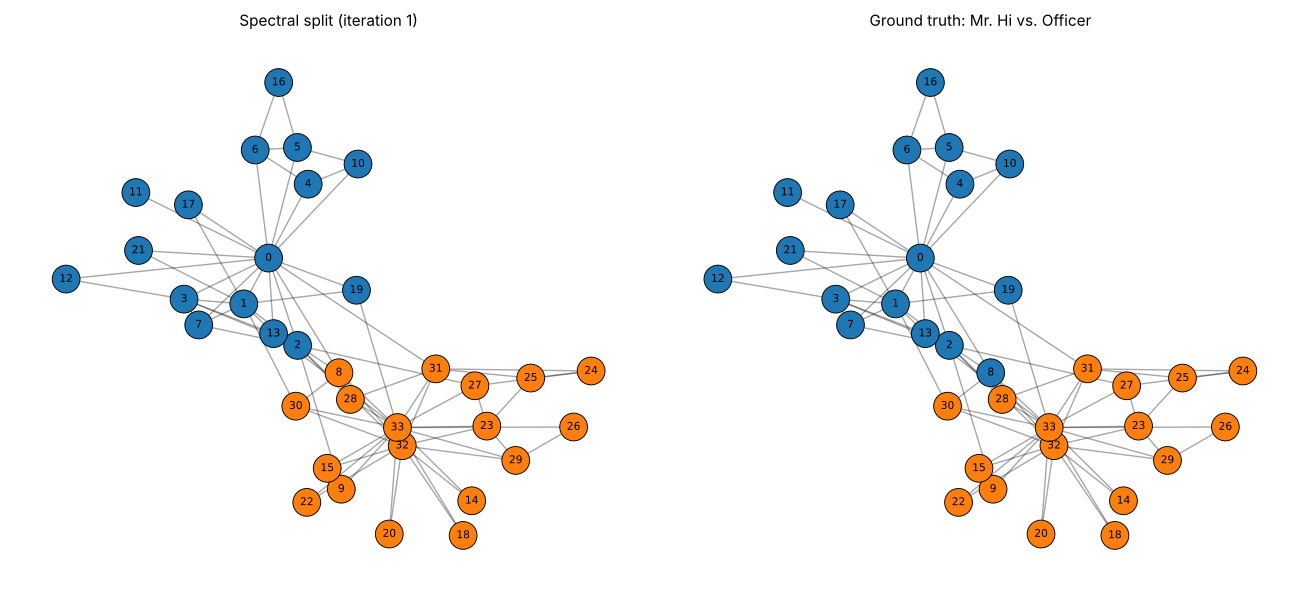

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
draw_partition(axes[0], history[1], "Spectral split (iteration 1)")
real = [[i for i in nodes if truth[i] == 1], [i for i in nodes if truth[i] == -1]]
draw_partition(axes[1], real, "Ground truth: Mr. Hi vs. Officer")
plt.tight_layout(); plt.show()

## 5. Node metrics after every split
**Interpretation used.** The four NetworkX metrics of the *whole* graph never change when we recolour nodes, so to make them respond to the community structure we compute them **within each node's current community**, i.e. on the induced subgraph $G[C]$ of the community containing the node. Iteration 0 is the whole graph. After each split every node gets a value computed on its own (smaller) community subgraph.

Notes: the induced subgraph of a community can in principle be disconnected; NetworkX's `closeness_centrality` handles that by scaling with the reachable component (Wasserman–Faust), and a single-node community gets 0 for betweenness, closeness and clustering, while NetworkX defines its degree centrality as 1. Degree centrality is also normalised by $|C|-1$ of the *community*, so values rise as communities shrink; compare ranks rather than absolute levels across iterations.

In [7]:
METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def metrics_for_partition(communities):
    """Compute each metric on every community's induced subgraph."""
    out = {name: {} for name in METRICS}
    for c in communities:
        H = G.subgraph(c)
        for name, fn in METRICS.items():
            vals = fn(H)
            for v in c:
                out[name][v] = vals[v]
    return out

# metric_history[metric][iteration] = {node: value}
metric_history = {name: {} for name in METRICS}
for t, comms in enumerate(history):
    res = metrics_for_partition(comms)
    for name in METRICS:
        metric_history[name][t] = res[name]

# Tidy DataFrames: rows = node, columns = iteration
metric_df = {name: pd.DataFrame(metric_history[name]).loc[nodes] for name in METRICS}
for name, df in metric_df.items():
    df.columns = [f"iter {t}" for t in df.columns]

# sanity check: iteration 0 equals NetworkX on the full graph
for name, fn in METRICS.items():
    full = fn(G)
    assert all(abs(full[v] - metric_history[name][0][v]) < 1e-12 for v in nodes)

metric_df["Degree centrality"].round(3).head(10)

,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.485,0.933,1.000,1.000,1.000
1,0.273,0.533,0.889,0.889,0.889
2,0.303,0.333,0.556,0.556,0.556
3,0.182,0.400,0.667,0.667,0.667
4,0.091,0.200,0.400,0.400,0.500
5,0.121,0.267,0.600,0.600,0.750
6,0.121,0.267,0.600,0.600,0.750
7,0.121,0.267,0.444,0.444,0.444
8,0.152,0.176,0.176,0.250,0.250
9,0.061,0.059,0.059,0.083,0.083


## 6. Evolution of the metrics across iterations
For each metric: (left) a line for every node, with the five nodes that have the highest *average* value highlighted and labelled while the rest are drawn in grey; (right) a heat-map of all 34 nodes × all iterations so every node can be read off.

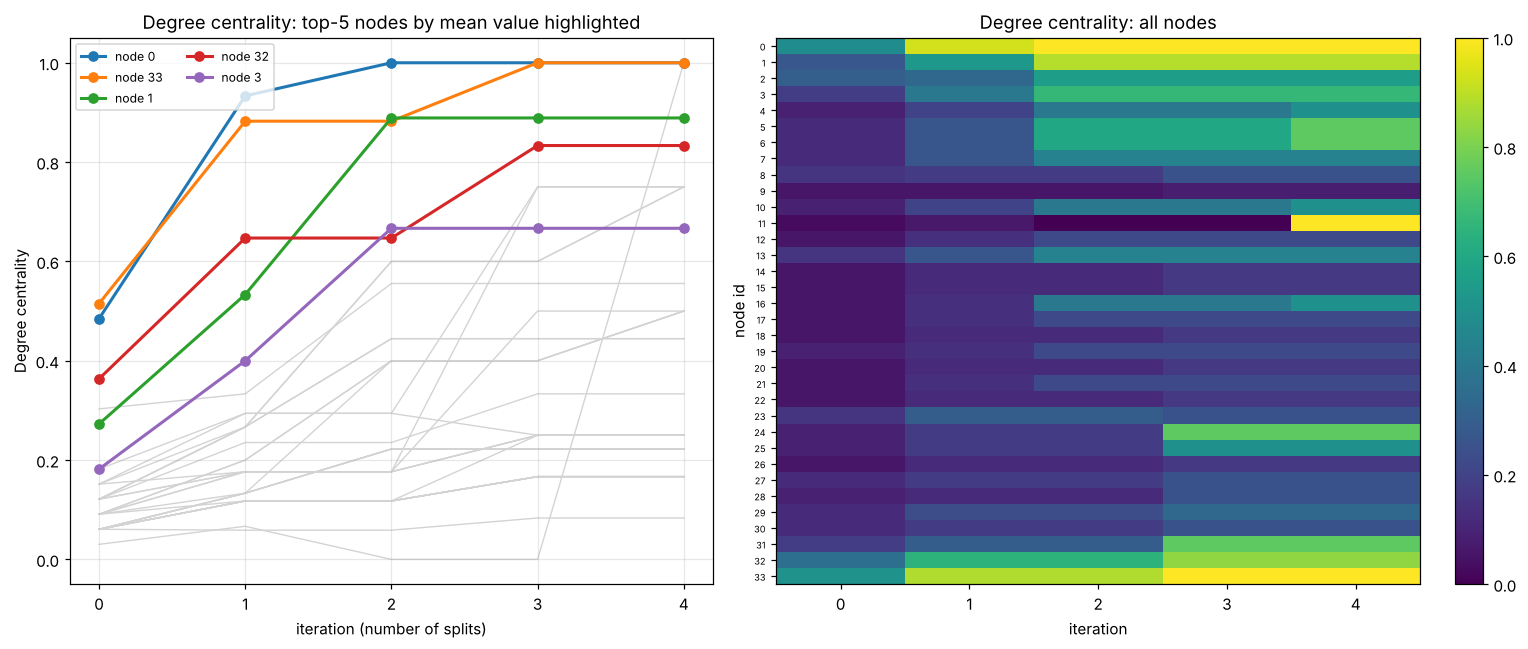

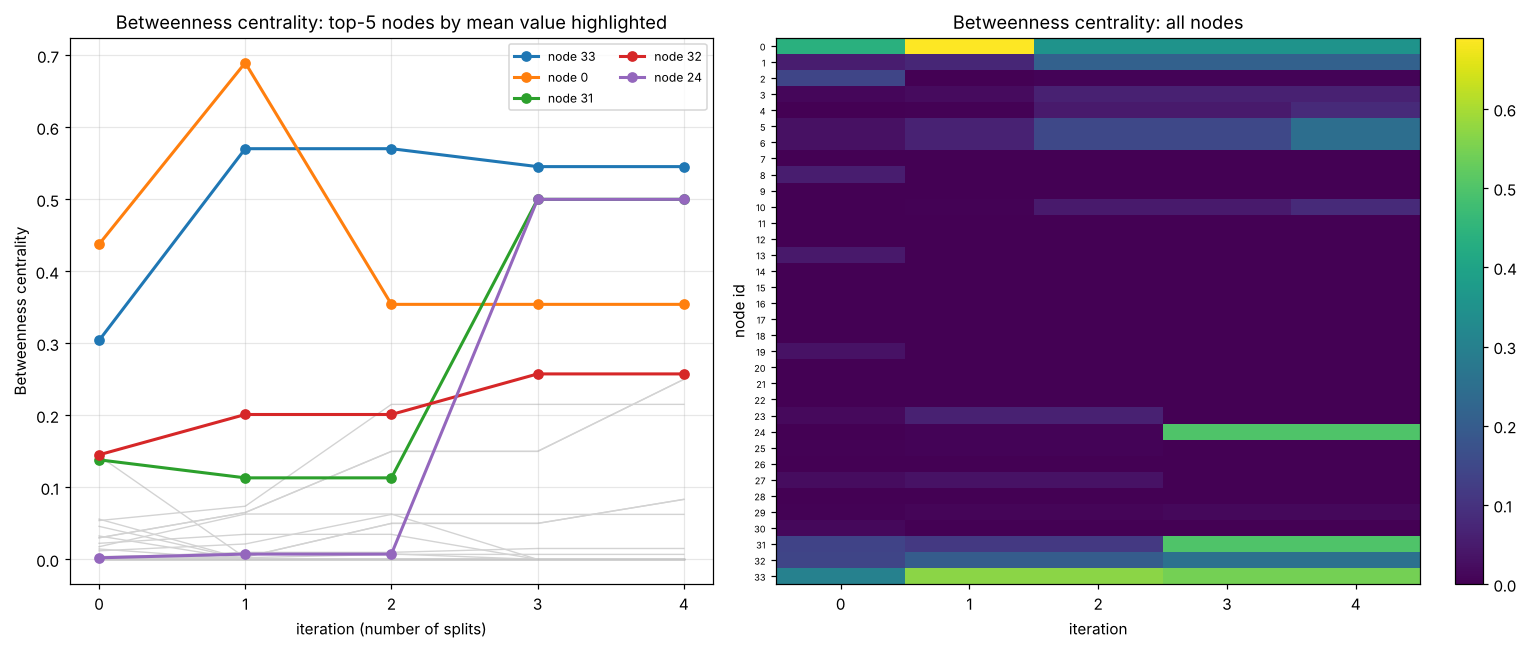

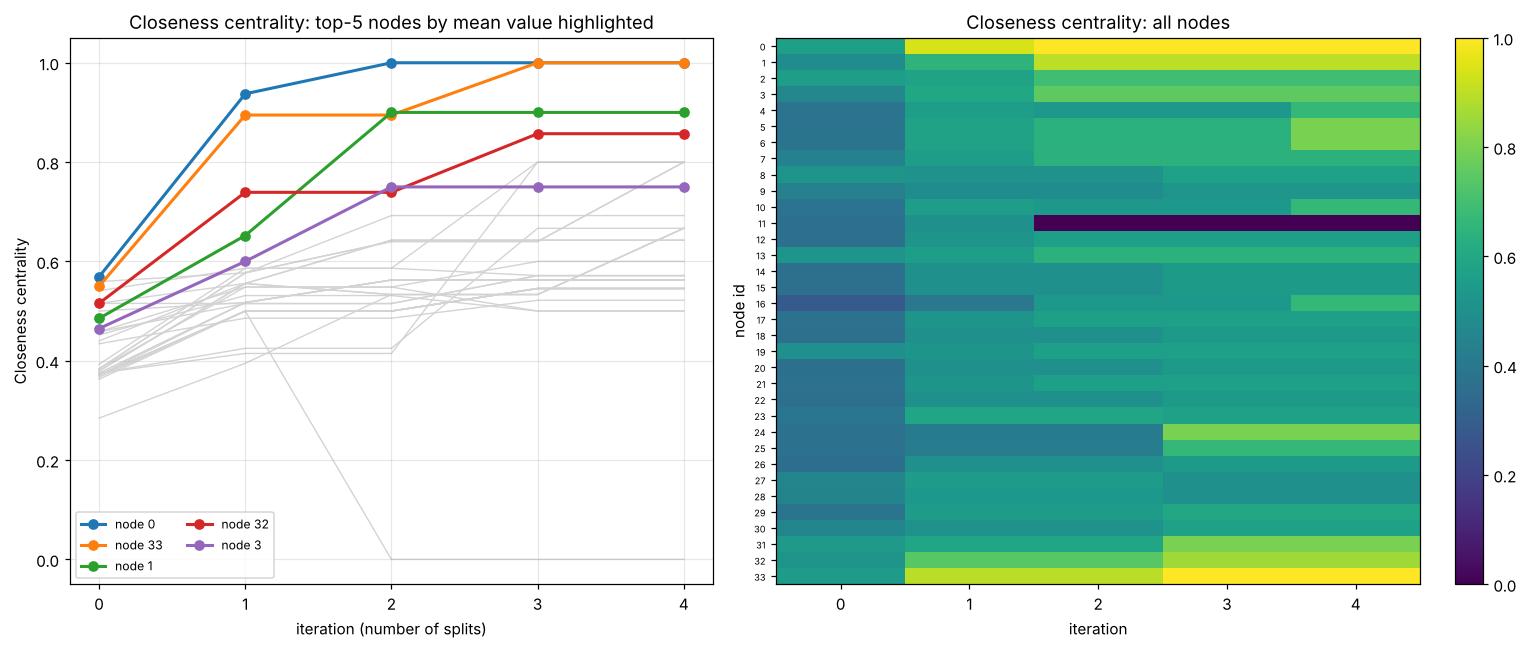

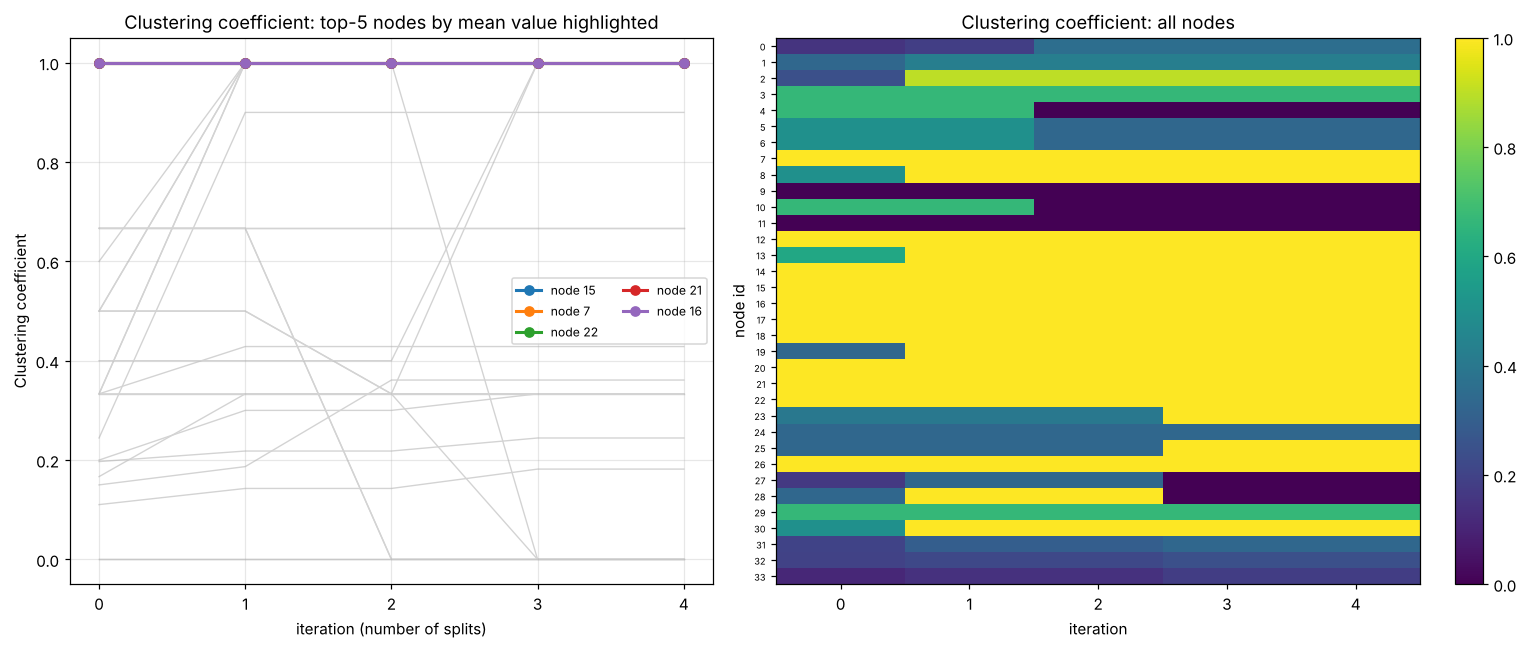

In [8]:
iters = list(range(n_iter + 1))
tab = plt.get_cmap("tab10")

for name, df in metric_df.items():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.1]})
    top = df.mean(axis=1).sort_values(ascending=False).index[:5]
    for v in nodes:
        if v not in top:
            ax1.plot(iters, df.loc[v].values, color="lightgrey", lw=0.9, zorder=1)
    for ci, v in enumerate(top):
        ax1.plot(iters, df.loc[v].values, marker="o", lw=2, color=tab(ci), label=f"node {v}", zorder=3)
    ax1.set_xticks(iters); ax1.set_xlabel("iteration (number of splits)"); ax1.set_ylabel(name)
    ax1.set_title(f"{name}: top-5 nodes by mean value highlighted"); ax1.legend(fontsize=8, ncol=2)
    ax1.grid(alpha=0.3)

    im = ax2.imshow(df.values, aspect="auto", cmap="viridis")
    ax2.set_xticks(range(len(iters))); ax2.set_xticklabels(iters)
    ax2.set_yticks(range(n)); ax2.set_yticklabels(nodes, fontsize=6)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node id"); ax2.set_title(f"{name}: all nodes")
    fig.colorbar(im, ax=ax2, fraction=0.04)
    plt.tight_layout(); plt.show()

Top-5 nodes (by mean value over all iterations) for each metric, and how often each is the community maximum:

In [9]:
rows = []
for name, df in metric_df.items():
    mean_rank = df.mean(axis=1).sort_values(ascending=False)
    # for each iteration, which node has the max value (ties -> all)
    wins = pd.Series(0, index=nodes)
    for col in df.columns:
        wins[df.index[np.isclose(df[col], df[col].max())]] += 1
    rows.append({"metric": name,
                 "top-5 by mean": list(mean_rank.index[:5]),
                 "#iterations as global max (node: count)": dict(wins[wins > 0].sort_values(ascending=False).head(5))})
display(pd.DataFrame(rows).set_index("metric"))

# The two faction leaders and the final community of every node
print("Degree of node 0 (Mr. Hi) / node 33 (Officer):", int(k[0]), "/", int(k[33]))

,top-5 by mean,#iterations as global max (node: count)
metric,,
Degree centrality,"[0, 33, 1, 32, 3]","{0: 4, 33: 3, 11: 1}"
Betweenness centrality,"[33, 0, 31, 32, 24]","{33: 3, 0: 2}"
Closeness centrality,"[0, 33, 1, 32, 3]","{0: 5, 33: 2}"
Clustering coefficient,"[15, 7, 22, 21, 16]","{7: 5, 12: 5, 22: 5, 14: 5, 15: 5}"


Degree of node 0 (Mr. Hi) / node 33 (Officer): 16 / 17


## 7. Discussion

**Method.** We followed Newman (2006): build $B = A - kk^\top/2m$, bisect each group by the sign of the leading eigenvector of its block $B^{(C)}$, and stop on a group when $\lambda_1^{(C)} \le 0$. On the Karate Club graph this gives 4 splits and 5 communities with final $Q = 0.4094$ (verified against `networkx.community.modularity`).

**First split vs. reality.** The first bisection ($\lambda_1 \approx 4.98$, $Q \approx 0.3715$) reproduces Zachary's real split for 33 of 34 members (97.1%). Only node 8 is placed on the other side. Node 8 has ties to both factions, so the graph alone cannot decide it. The modularity of the true split is 0.3582, slightly *lower* than that of the spectral split, so the algorithm finds a better-scoring cut than the one history produced.

**Later splits.** Each further split lowers the leading eigenvalue (4.98, 2.94, 2.50, 2.15) and adds less modularity (total $Q$ rises by about 0.018, 0.018 and 0.001). The Mr. Hi side breaks into a dense core around nodes 0, 1, 2, 3 and a group around nodes 4, 5, 6, 10, 16; the Officer side breaks into a large group around 32 and 33 and a group around 24, 25, 27, 28, 31. The last split removes node 11, a degree-1 leaf attached to node 0, as a singleton. This is a side-effect of using the plain block of $B$ (see Section 8), and the generalised matrix does not produce it.

**Which nodes stay central.** Node 0 (Mr. Hi) and node 33 (the Officer) are the two hubs throughout. They are first and second in mean degree centrality and closeness, and at the top for betweenness as well, followed by bridge-like nodes such as 31 and 32 (and 2 in the whole graph). Node 0 is the maximum of closeness in every iteration, and one of the two maxima for degree and betweenness in most. Nodes 1, 3 and 32 follow as secondary hubs. So the two leaders stay central *no matter how finely the graph is split*, which fits the story that the club split around them.

**How community structure changes the metrics.**
- *Degree and closeness* are computed inside each community, so they rise for almost everyone as the communities shrink (the denominators $|C|-1$ get smaller). What matters is the *rank*: hubs keep their rank because most of their edges point into their own community. A node whose edges cross communities (such as node 8 or the bridge nodes 2, 31, 32) loses relative standing after the split that separates its neighbours.
- *Betweenness* depends most on where the cuts fall. In the whole graph the highest values are 0 (0.44), 33 (0.30), and then 2, 32 and 31 (about 0.14 each), because shortest paths between the two factions pass through a few well-connected nodes. After splitting, paths are only counted inside each community, so a node's score now measures brokerage within its own group. Node 24 is a clear example: its whole-graph betweenness is about 0.002, but it ranks in the top five by mean value because it becomes a connector inside the small group it ends up in.
- *Clustering* behaves in the opposite way to the hubs. The highest averages belong to low-degree nodes (15, 7, 22, 21, 16) whose few neighbours are also tied to each other, i.e. members of tight cliques at the periphery. Hubs link otherwise unconnected people, so their clustering is low. As communities become denser after each split, clustering goes up for many nodes and many nodes tie at 1.0, which is why the "maximum per iteration" table is uninformative for this metric and the mean ranking is used instead.

**Caveats.** (i) The metrics are computed on each community's induced subgraph, which is our interpretation of "after each split" (the whole-graph values would not change). (ii) The handout's plain block $B_{[C,C]}$ differs from Newman's generalised matrix for proper subgroups; with the generalised matrix and a $\Delta Q>0$ check we get 4 communities and $Q = 0.3934$, versus 5 communities and $Q = 0.4094$ for the handout version. Both are shown in Section 8. (iii) The result is a single heuristic (spectral bisection, no refinement) and not the global maximum of modularity.


## 8. Extra (optional): block-restricted $B^{(C)}$ vs. Newman's generalised matrix
The handout defines $B^{(C)}$ as the plain block of the global $B$. That is what the code above uses. Be aware that, for a *proper* subgroup, the exact modularity change from splitting $C$ is governed by the **generalised** matrix of Newman (2006, eq. 6)

$$B^{(C)}_{ij}= B_{ij}-\delta_{ij}\sum_{l\in C}B_{il},$$

which subtracts each row's sum inside the block so that $B^{(C)}\mathbf 1=0$ again. The plain block does not satisfy this, so $\tfrac1{4m}s^\top B_{[C,C]}s$ is not exactly $\Delta Q$ when $C\neq V$. For the first split ($C=V$) the two matrices coincide, because the row sums of $B$ are 0. We run both variants and compare.

In [10]:
def spectral_split_generalised(C, B=B, m=m, tol=TOL):
    C = list(C)
    if len(C) < 2:
        return None
    B_blk = B[np.ix_(C, C)]
    B_C = B_blk - np.diag(B_blk.sum(axis=1))      # Newman's generalised B^(g)
    vals, vecs = np.linalg.eigh(B_C)
    lam1, u1 = vals[-1], vecs[:, -1]
    if lam1 <= tol:
        return None
    s = np.where(u1 > 0, 1, -1)
    if abs(s.sum()) == len(s):
        return None
    Cp = [c for c, si in zip(C, s) if si == 1]
    Cm = [c for c, si in zip(C, s) if si == -1]
    dQ = s @ B_C @ s / (4 * m)
    if dQ <= tol:                                  # Newman: only split if dQ > 0 for the sign-rounded s
        return None
    return Cp, Cm, lam1, dQ

hist_g, log_g = recursive_spectral_partition(nodes, split_fn=spectral_split_generalised)

def describe(h):
    return sorted([sorted(c) for c in h[-1]], key=lambda c: c[0])

print(f"Handout (plain block)   : {len(history[-1])} communities, Q = {partition_modularity(history[-1]):.4f}")
print(f"Newman (generalised)    : {len(hist_g[-1])} communities, Q = {partition_modularity(hist_g[-1]):.4f}")
print("Q trajectory (plain)      :", [round(float(r['Q']),4) for r in log])
print("Q trajectory (generalised):", [round(float(r['Q']),4) for r in log_g])
print("Same final partition?   :", describe(history) == describe(hist_g))
for tag, h in [("plain", history), ("generalised", hist_g)]:
    print(f"\n{tag}:")
    for c in sorted(h[-1], key=lambda c: -len(c)):
        print("  ", sorted(c))

Handout (plain block)   : 5 communities, Q = 0.4094
Newman (generalised)    : 4 communities, Q = 0.3934
Q trajectory (plain)      : [0.0, 0.3715, 0.3898, 0.4081, 0.4094]
Q trajectory (generalised): [0.0, 0.3715, 0.3727, 0.3934]
Same final partition?   : False

plain:
   [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
   [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
   [24, 25, 27, 28, 31]
   [4, 5, 6, 10, 16]
   [11]

generalised:
   [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
   [1, 2, 3, 7, 12, 13, 17, 19, 21]
   [0, 4, 5, 6, 10, 11, 16]
   [23, 24, 25, 27, 28, 31]
